# Assignment 3 — Boosting: Insurance Charges

**Goal:** predict an individual's medical insurance `charges` (regression) from `age`, `sex`, `bmi`, `children` and `smoker`.

**Boosting algorithms compared:** AdaBoost, Gradient Boosting, Histogram Gradient Boosting, XGBoost, LightGBM, CatBoost. (Linear Regression is included only as a baseline.)

Each boosting model is tuned with `GridSearchCV` (5-fold CV on the training set) and then evaluated on an untouched 20 % test set.

**Metrics:** R² ↑ (main criterion), MAE ↓, RMSE ↓, 5-fold CV R² ↑.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
sns.set_theme(style='whitegrid')
RS = 42

## 1. Load & explore the data

In [2]:
df = pd.read_csv('data/insurance_pre.csv')
print(df.shape); print('Missing values:', df.isnull().sum().sum())
df.head()

(1338, 6)
Missing values: 0


,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520


In [3]:
df.describe(include='all')

,age,sex,bmi,children,smoker,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338.000000
unique,NaN,2,NaN,NaN,2,NaN
top,NaN,male,NaN,NaN,no,NaN
freq,NaN,676,NaN,NaN,1064,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,16639.912515


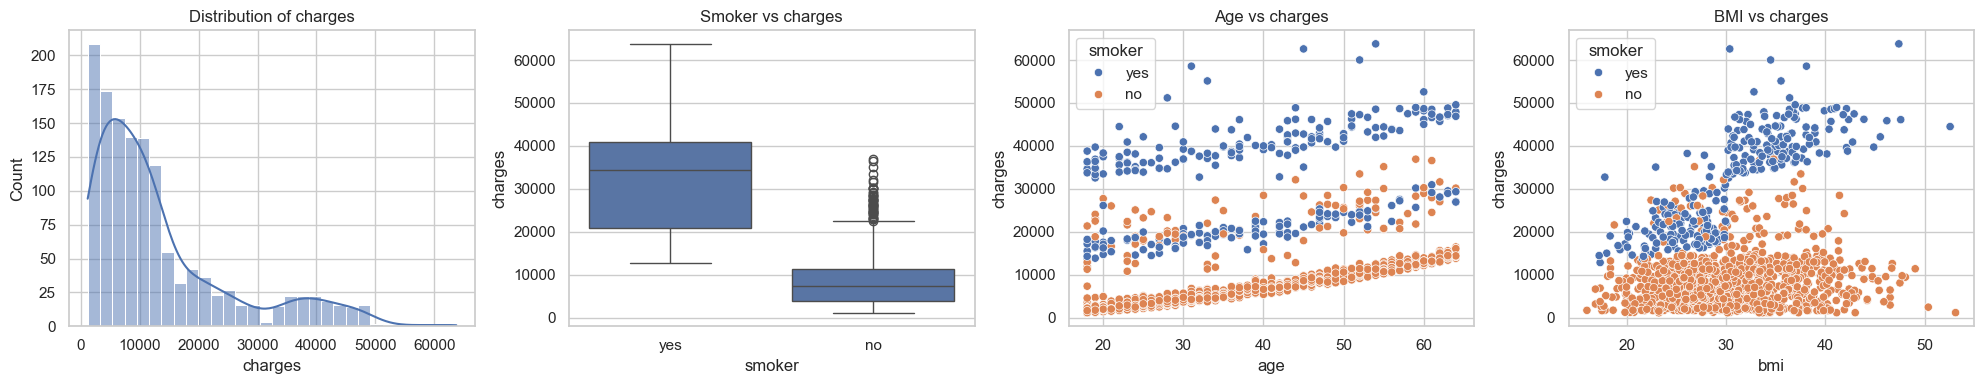

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
sns.histplot(df['charges'], kde=True, ax=ax[0]); ax[0].set_title('Distribution of charges')
sns.boxplot(x='smoker', y='charges', data=df, ax=ax[1]); ax[1].set_title('Smoker vs charges')
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, ax=ax[2]); ax[2].set_title('Age vs charges')
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, ax=ax[3]); ax[3].set_title('BMI vs charges')
plt.tight_layout(); plt.savefig('results/boosting_eda.png', dpi=120); plt.show()

## 2. Pre-processing
Categorical columns (`sex`, `smoker`) are one-hot encoded with `drop_first=True`. Tree-based boosting does not need feature scaling.

Train: (1070, 5)  Test: (268, 5)


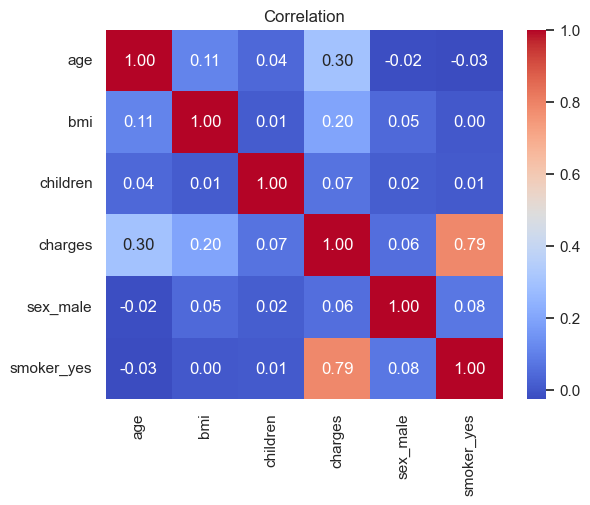

In [5]:
data = pd.get_dummies(df, columns=['sex', 'smoker'], drop_first=True, dtype=int)
X, y = data.drop(columns='charges'), data['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)
print('Train:', X_train.shape, ' Test:', X_test.shape)
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.title('Correlation'); plt.show()

## 3. Hyper-parameter tuning & training of boosting models

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=RS)
search_space = {
    'AdaBoost': (AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), random_state=RS),
                 {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.05, 0.1]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=RS),
                 {'n_estimators': [100, 200, 300], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [2, 3, 4]}),
    'Histogram Gradient Boosting': (HistGradientBoostingRegressor(random_state=RS),
                 {'max_iter': [100, 200, 300], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 4, None]}),
    'XGBoost': (XGBRegressor(random_state=RS, n_jobs=-1, verbosity=0),
                 {'n_estimators': [100, 200, 300], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [2, 3, 4]}),
    'LightGBM': (LGBMRegressor(random_state=RS, verbose=-1),
                 {'n_estimators': [100, 200, 300], 'learning_rate': [0.03, 0.05, 0.1], 'num_leaves': [7, 15, 31]}),
    'CatBoost': (CatBoostRegressor(random_state=RS, verbose=0),
                 {'iterations': [200, 400], 'learning_rate': [0.03, 0.05, 0.1], 'depth': [3, 4, 6]}),
}
best_models, best_params = {}, {}
for name, (est, grid) in search_space.items():
    gs = GridSearchCV(est, grid, cv=kf, scoring='r2', n_jobs=-1).fit(X_train, y_train)
    best_models[name], best_params[name] = gs.best_estimator_, gs.best_params_
    print(f'{name:30s} best params: {gs.best_params_}')
best_models['Linear Regression (baseline)'] = LinearRegression().fit(X_train, y_train)

AdaBoost                       best params: {'learning_rate': 0.01, 'n_estimators': 50}


Gradient Boosting              best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


Histogram Gradient Boosting    best params: {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 100}


XGBoost                        best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


LightGBM                       best params: {'learning_rate': 0.05, 'n_estimators': 100, 'num_leaves': 7}


CatBoost                       best params: {'depth': 3, 'iterations': 200, 'learning_rate': 0.03}


## 4. Evaluate on the test set

In [7]:
rows, preds = [], {}
for name, m in best_models.items():
    p = m.predict(X_test); preds[name] = p
    rows.append({'Algorithm': name,
                 'R2 Score': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'CV R2 (5-fold)': cross_val_score(m, X, y, cv=kf, scoring='r2').mean()})
results = pd.DataFrame(rows).sort_values('R2 Score', ascending=False).reset_index(drop=True)
results.index += 1
results.round(4)

,Algorithm,R2 Score,MAE,RMSE,CV R2 (5-fold)
1,XGBoost,0.8840,2441.8062,4243.9386,0.8577
2,LightGBM,0.8820,2440.5365,4279.6448,0.8556
3,CatBoost,0.8810,2446.3635,4297.6337,0.8573
4,Gradient Boosting,0.8791,2476.4557,4331.5635,0.8549
5,Histogram Gradient Boosting,0.8787,2476.1500,4340.2215,0.8572
6,AdaBoost,0.8721,2743.2084,4456.8214,0.8513
7,Linear Regression (baseline),0.7811,4213.4848,5829.1729,0.7399


In [8]:
results.round(4).to_csv('results/boosting_results.csv', index_label='Rank')
pd.Series({k: str(v) for k, v in best_params.items()}, name='Best hyper-parameters').to_csv('results/boosting_best_params.csv')
best = results.iloc[0]['Algorithm']
print(f"BEST BOOSTING ALGORITHM: {best}  ->  R2 = {results.iloc[0]['R2 Score']:.4f}, "
      f"MAE = {results.iloc[0]['MAE']:.2f}, RMSE = {results.iloc[0]['RMSE']:.2f}")

BEST BOOSTING ALGORITHM: XGBoost  ->  R2 = 0.8840, MAE = 2441.81, RMSE = 4243.94


## 5. Visual comparison

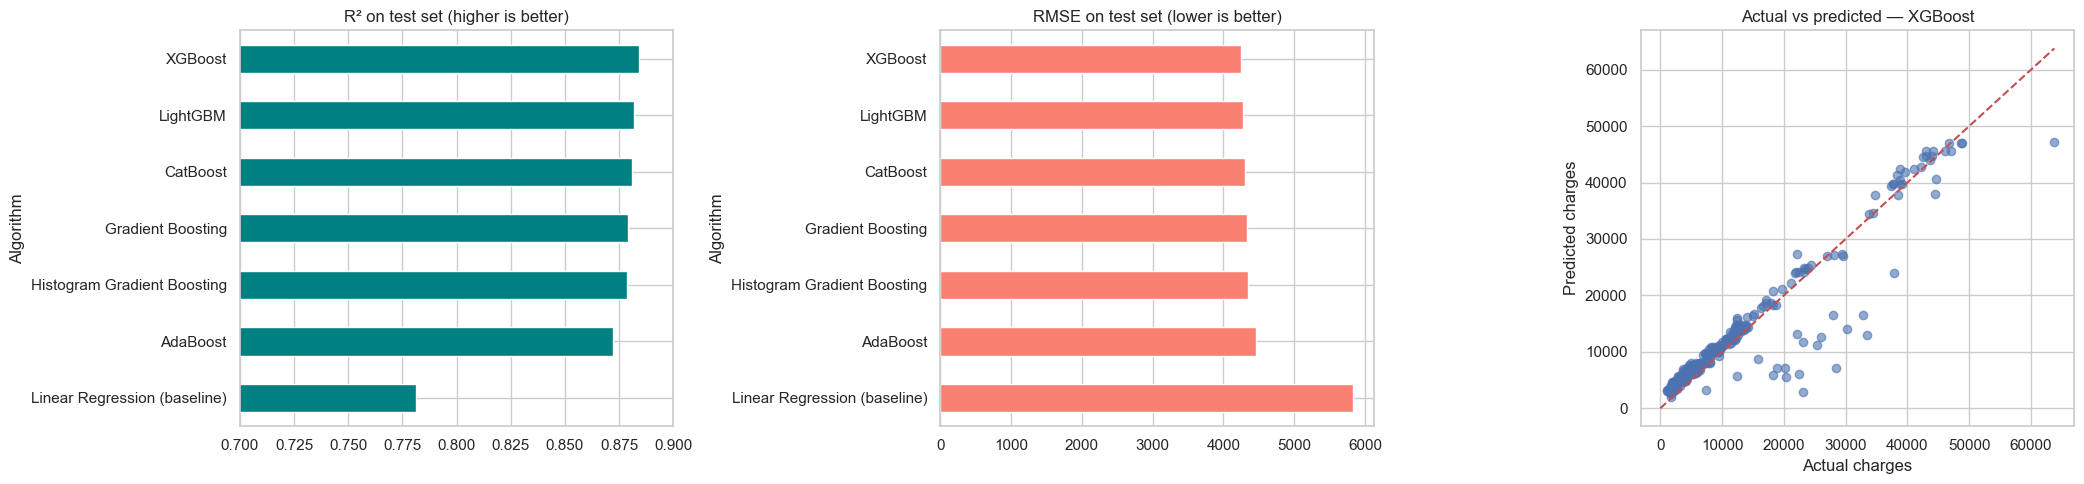

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(21, 5))
r = results.set_index('Algorithm')
r['R2 Score'].plot.barh(ax=ax[0], color='teal', xlim=(0.7, 0.9)); ax[0].invert_yaxis(); ax[0].set_title('R² on test set (higher is better)')
r['RMSE'].plot.barh(ax=ax[1], color='salmon'); ax[1].invert_yaxis(); ax[1].set_title('RMSE on test set (lower is better)')
ax[2].scatter(y_test, preds[best], alpha=0.6); lim = [0, y_test.max()]
ax[2].plot(lim, lim, 'r--'); ax[2].set_xlabel('Actual charges'); ax[2].set_ylabel('Predicted charges'); ax[2].set_title(f'Actual vs predicted — {best}')
plt.tight_layout(); plt.savefig('results/boosting_comparison.png', dpi=120); plt.show()

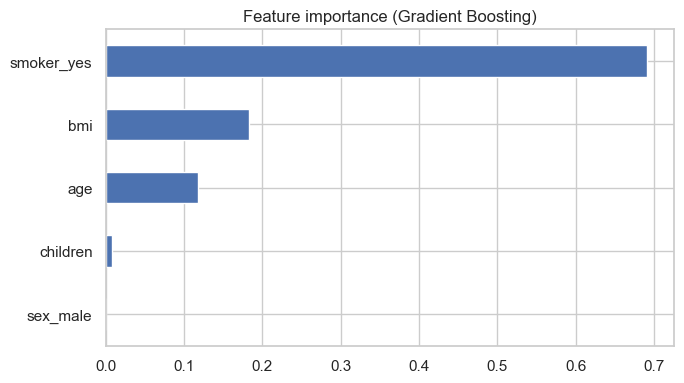

In [10]:
imp = pd.Series(best_models['Gradient Boosting'].feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(7, 4), title='Feature importance (Gradient Boosting)')
plt.tight_layout(); plt.savefig('results/boosting_feature_importance.png', dpi=120); plt.show()

## 6. Conclusion
All tuned boosting models explain roughly 86–88 % of the variance in insurance charges, clearly beating the linear baseline (~78 %), because charges depend on non-linear interactions (smoker × BMI, smoker × age) that trees capture automatically. `smoker` is by far the most important feature, followed by `bmi` and `age`. The best boosting algorithm is shown in the results table above.